In [1]:
pip install captum matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import numpy as np

import sys
sys.path.append("../")

from utils.set_seed import set_seed
from data.utils.r_peak_processing import detect_r_peaks
from models.catnet import CatNet
from interpretability_methods.ig import run_ig
from interpretability_methods.lime import run_lime
import pandas as pd

c:\Users\oladipea\Documents\EKG-HAN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
set_seed(10)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device("cpu")

In [4]:
catnet = torch.load("model_pths/catnet.pth", map_location="cpu", weights_only=False)

catnet_model =  CatNet(num_channels=12,
                d_model=128, num_heads=4, dff=128, dropout_rate=0.3,
                num_classes=11, apply_softmax=False)

dummy = torch.zeros(1, 5000, 12)
catnet_model._init_fc_head(dummy, device="cpu")

catnet_model.load_state_dict(catnet)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device("cpu")
catnet_model.to(device)
catnet_model.eval()

CatNet(
  (conv1): Conv1d(12, 32, kernel_size=(21,), stride=(1,), padding=(10,))
  (bn1): GroupNorm(8, 32, eps=1e-05, affine=True)
  (ca1): ChannelAttention(
    (mlp): Sequential(
      (0): Linear(in_features=32, out_features=4, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=4, out_features=32, bias=True)
    )
  )
  (pool1): MaxPool1d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 32, kernel_size=(23,), stride=(1,), padding=(11,))
  (bn2): GroupNorm(8, 32, eps=1e-05, affine=True)
  (ca2): ChannelAttention(
    (mlp): Sequential(
      (0): Linear(in_features=32, out_features=4, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=4, out_features=32, bias=True)
    )
  )
  (pool2): MaxPool1d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (conv3): Conv1d(32, 64, kernel_size=(25,), stride=(1,), padding=(12,))
  (bn3): GroupNorm(8, 64, eps=1e-05, affine=True)
  (ca3): ChannelAttention(


In [5]:
samples = np.load(r"samples/A.npy", allow_pickle=True)
metadata = pd.read_csv("metadata.csv")

In [6]:
torch.use_deterministic_algorithms(False)
misclassified_samples = []
properly_classified_samples = []
for idx, sample in enumerate(samples[10:80]):
    sample = torch.tensor(sample['ecg']).unsqueeze(dim=0).transpose(1,2).to(device)
    predicted = torch.argmax(catnet_model(sample), dim=1)[0]
    if predicted != 0:
        misclassified_samples.append(idx)
    if predicted == 0:
        properly_classified_samples.append(idx)

print(len(properly_classified_samples), len(misclassified_samples))

65 5


   ECG_ID AHA_Code Patient_ID  Age Sex     N        Date
1  A00002        1     S00002   32   M  6000  2019-09-03
Computing Integrated Gradients attributions...


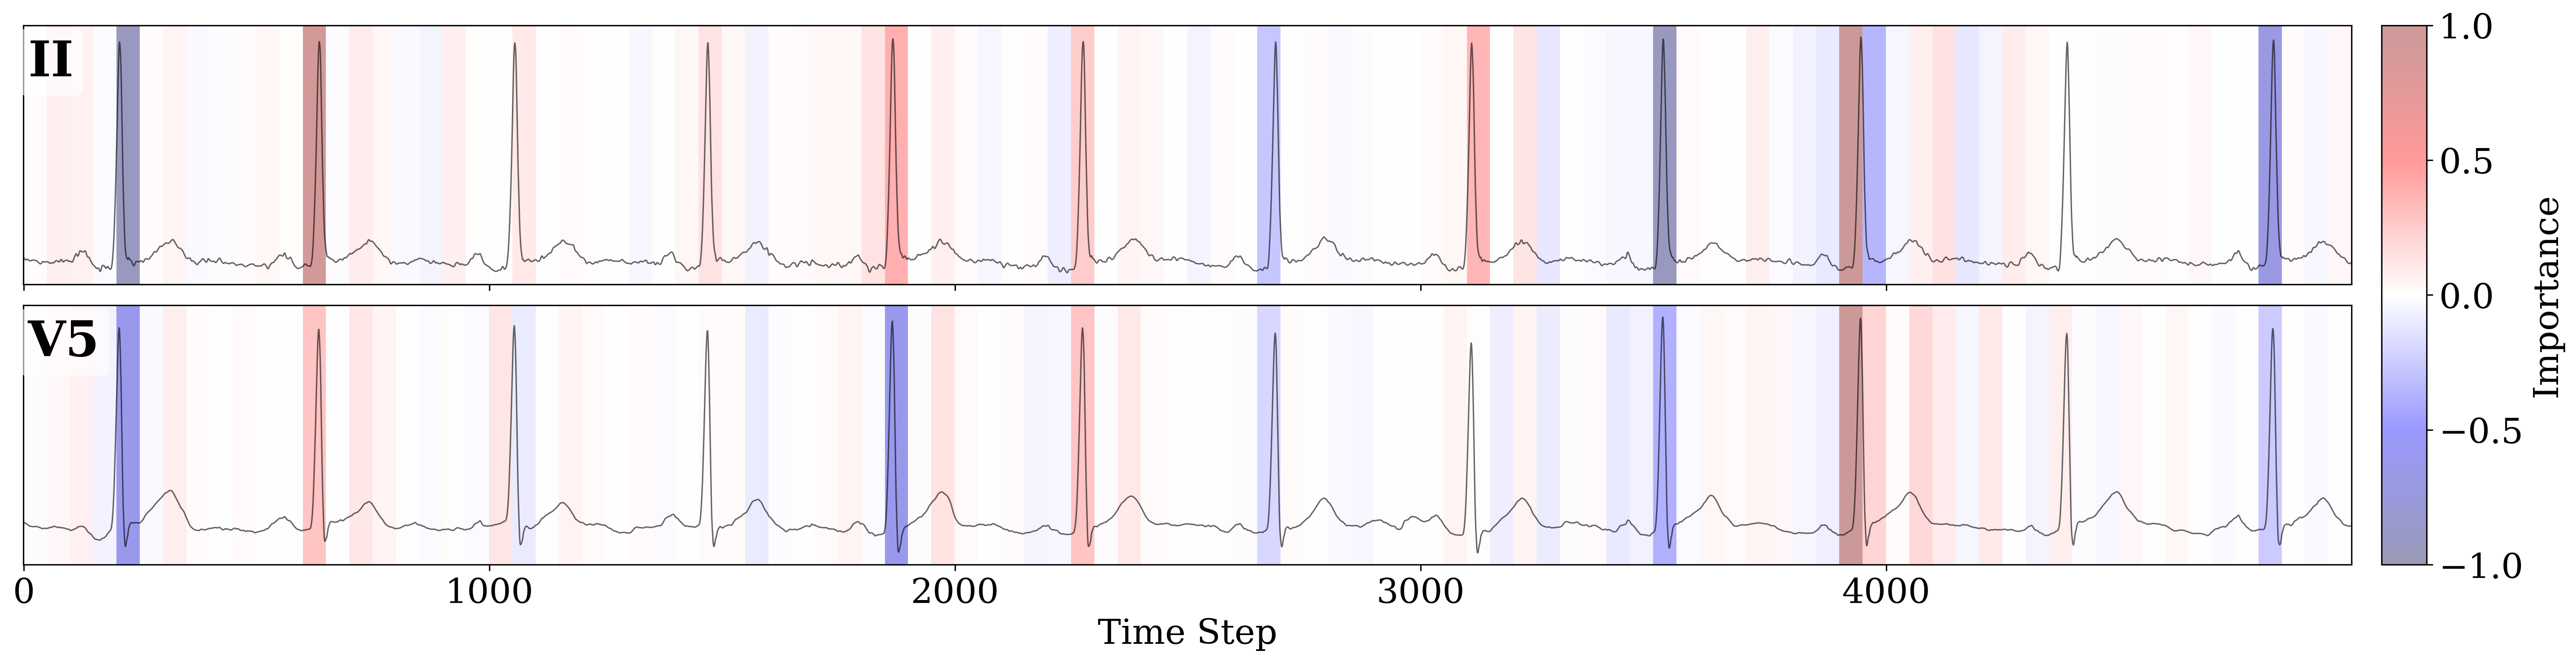

Attribution Range (Lead II): -0.9343 to 1.0000
Mean Abs Attribution (Lead II): 0.0948
Number of windows: 100
Window size: 50 samples
RR mode: n/a
Actual label 0 - . Predicted 0


In [7]:
idx = 0
x = torch.tensor(samples[idx]['ecg'], dtype=torch.float32) 
x = x[:, :5000].unsqueeze(0).transpose(1, 2).to(device)  
print(metadata[metadata['ECG_ID'] == samples[idx]['ecg_id']])

catnet_ig_attr = run_ig(model=catnet_model, x=x, y_true_description="", y_true=0, baseline='zero', window_size=50, leads=[1,10])

   ECG_ID AHA_Code Patient_ID  Age Sex     N        Date
1  A00002        1     S00002   32   M  6000  2019-09-03
ECG LIME features: 1200
Computing LIME attributions...


Lime attribution: 100%|██████████| 100/100 [00:27<00:00,  3.67it/s]


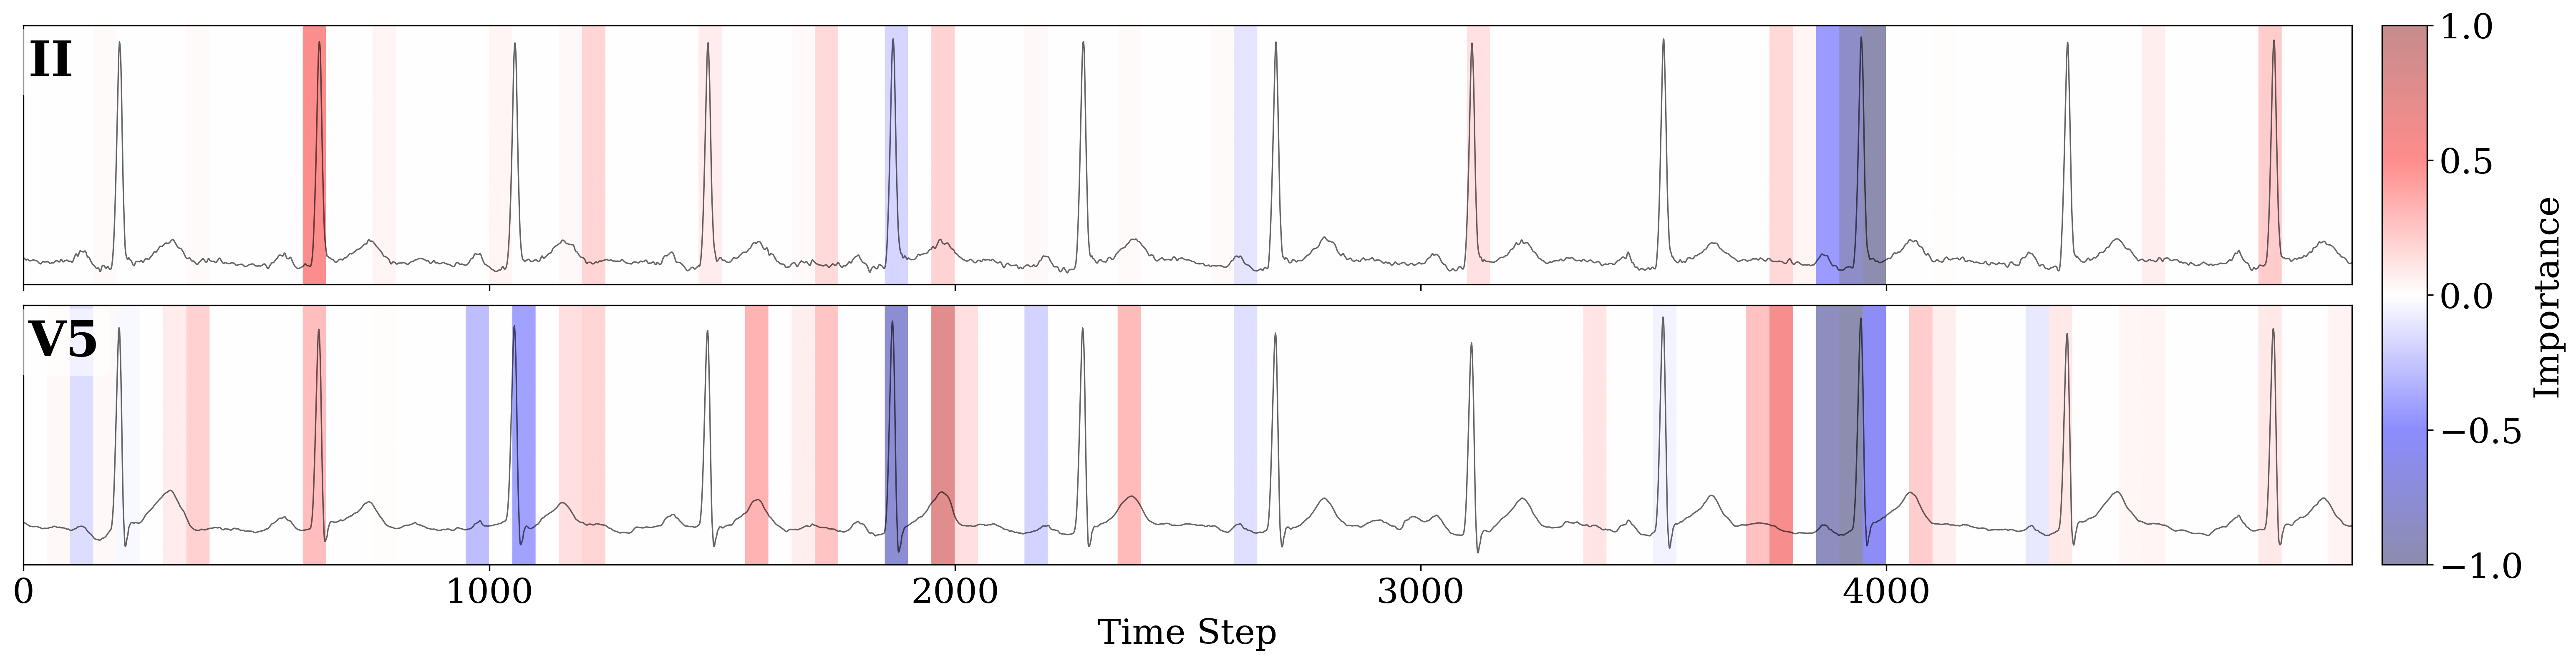

Lead  II | Range [-1.000, 0.516] | Mean |attr|: 0.0458
Lead  V5 | Range [-1.000, 0.744] | Mean |attr|: 0.0892

RR mode: n/a
Actual label 0 - . Predicted 0


In [8]:
idx = 0
x = torch.tensor(samples[idx]['ecg'], dtype=torch.float32) 
x = x[:, :5000].unsqueeze(0).transpose(1, 2).to(device)  
print(metadata[metadata['ECG_ID'] == samples[idx]['ecg_id']])

catnet_lime_attr = run_lime(model=catnet_model, x=x, y_true_description="", y_true=0, baseline='zero', leads=[1,10])